Dataset Shape: (10000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 937.6 KB
None

Missing Values:
 customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
bal

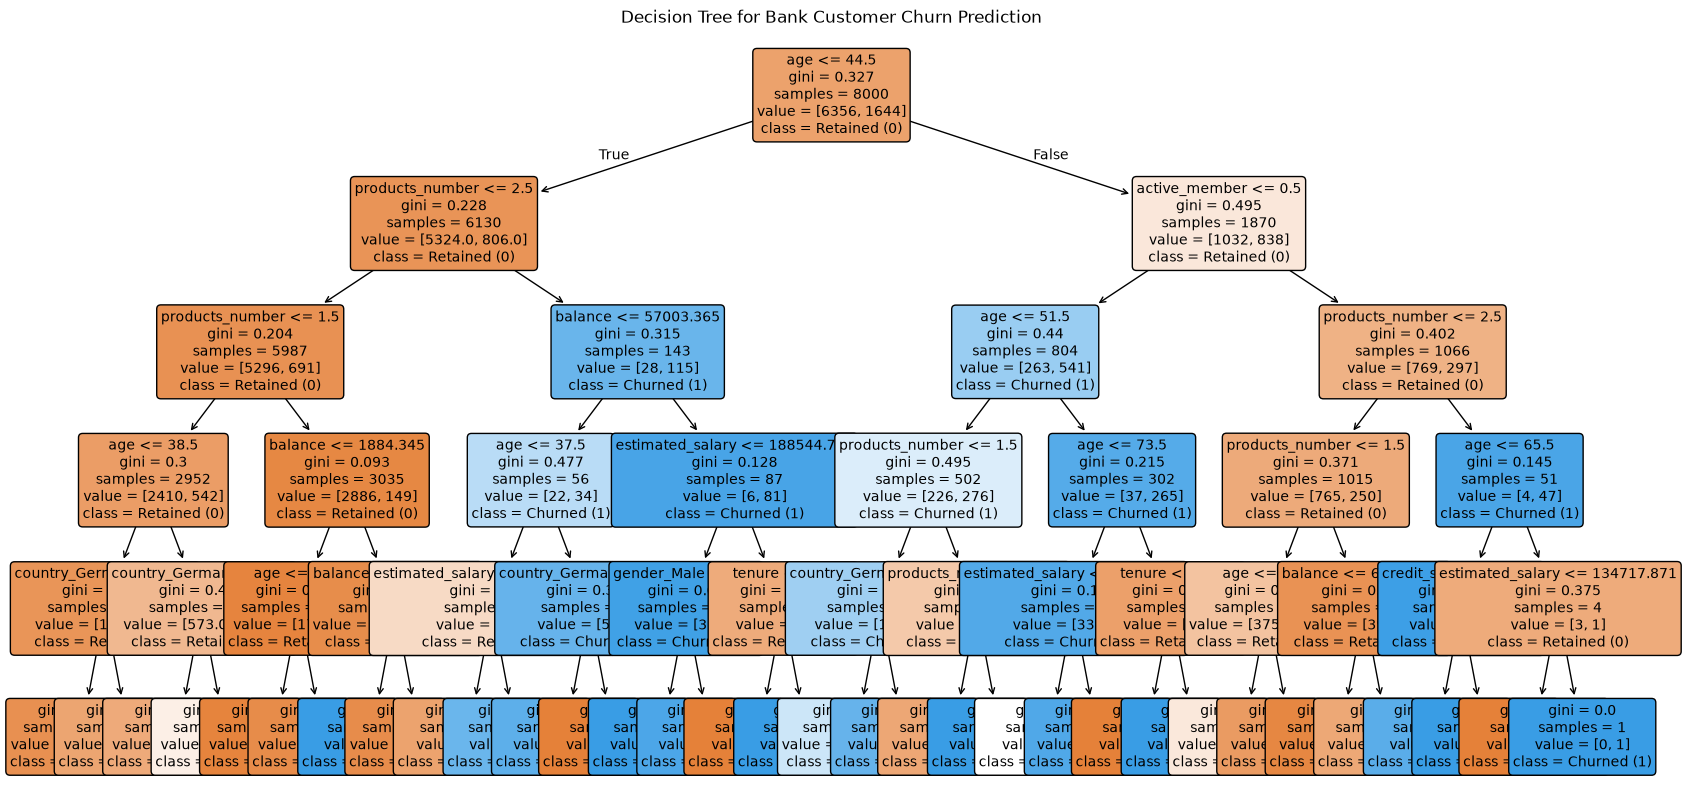

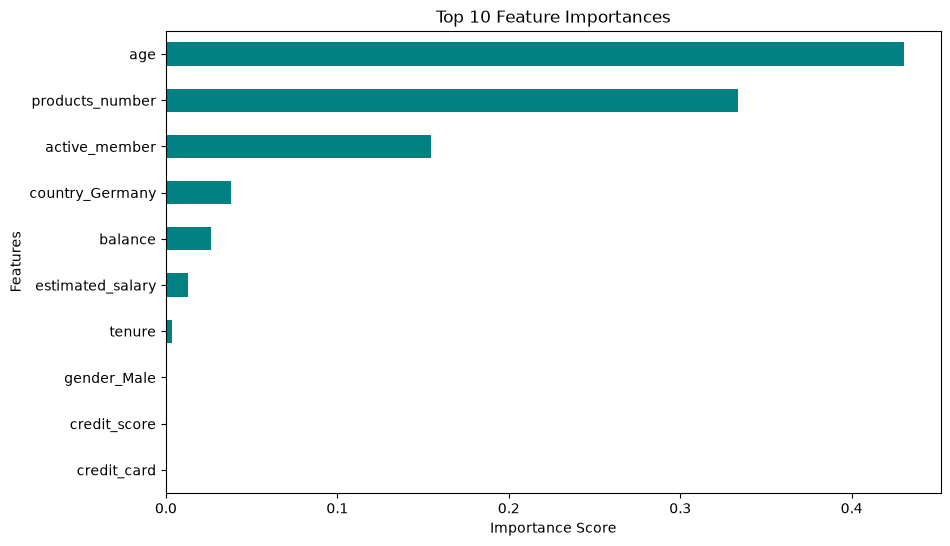

Top Influential Features:
age                 0.430532
products_number     0.333907
active_member       0.154772
country_Germany     0.037785
balance             0.026223
estimated_salary    0.012811
tenure              0.003367
gender_Male         0.000339
credit_score        0.000264
credit_card         0.000000
dtype: float64


In [3]:
import pandas as pd  #Pragya Singahl , CU24220050 ,43
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# 1. Load the dataset  #Pragya Singahl , CU24220050 ,43
df = pd.read_csv('Bank Customer Churn Prediction.csv')
print("Dataset Shape:", df.shape)
# 2. Data Preprocessing and Feature Engineering
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())

columns_to_drop = [col for col in ['customer_id', 'id', 'CustomerId', 'Surname'] if col in df.columns]
df = df.drop(columns=columns_to_drop, errors='ignore')

df = pd.get_dummies(df, drop_first=True)
# Define features (X) and target (y)  #Pragya Singahl , CU24220050 ,43
target_column = 'churn' if 'churn' in df.columns else 'Exited'
if target_column not in df.columns:
    for col in df.columns:
        if 'churn' in col.lower() or 'exited' in col.lower():
            target_column = col
            break

X = df.drop(columns=[target_column])
y = df[target_column]
print(f"Target column identified as: {target_column}")

# 3. Split the Dataset  #Pragya Singahl , CU24220050 ,43
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# 4. Train the Decision Tree Classifier  #Pragya Singahl , CU24220050 ,43
clf = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# 5. Predict and Evaluate the Model  #Pragya Singahl , CU24220050 ,43
y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"\nAccuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}\n")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Visualize the Decision Tree  #Pragya Singahl , CU24220050 ,43
plt.figure(figsize=(20, 10))
plot_tree(clf, feature_names=X.columns.tolist(), class_names=['Retained (0)', 'Churned (1)'], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Bank Customer Churn Prediction")
plt.show()

# 7. Feature Importance Analysis  #Pragya Singahl , CU24220050 ,43
feature_importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importances.head(10).plot(kind='barh', color='teal')
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()

print("Top Influential Features:")
print(feature_importances.head(10))